In [1]:
import sys
sys.path.insert(0, "..")  # so "utils" (in the project root) can be imported from src/

from utils.modelling import *

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
Xtrain.head()

,HEIGHT,SPEED,DISTANCE,INCIDENT_MONTH,AC_CLASS,AC_MASS,NUM_ENGS,TYPE_ENG,PHASE_OF_FLIGHT,TIME_OF_DAY,...,STR_FUSE,STR_LG,STR_TAIL,STR_LGHTS,STR_OTHER,BodyMass,ImpactEnergy,log_ImpactEnergy,SpeciesGroup,y_bin
75732,40.0,NaN,0.0,7,airplane,3.0,2.0,turbofan,Approach,Dusk,...,0,0,0,0,0,NaN,NaN,NaN,Unknown,0
83676,1900.0,200.0,1.0,7,airplane,4.0,2.0,turbofan,Climb,Day,...,0,0,0,0,0,NaN,NaN,NaN,Unknown,0
60739,NaN,NaN,NaN,6,airplane,4.0,2.0,turbofan,NaN,NaN,...,0,0,0,0,0,0.1001,NaN,NaN,Passeriformes,0
118702,0.0,NaN,0.0,6,airplane,5.0,2.0,turbofan,Landing Roll,Day,...,0,0,0,0,1,NaN,NaN,NaN,Unknown,0
23188,NaN,NaN,NaN,10,airplane,3.0,2.0,turbofan,Descent,NaN,...,0,0,0,0,0,NaN,NaN,NaN,Unknown,0


In [4]:
# multinomial logistic regression
def make_multinomial_logistic_model(model="A"):
    return make_pipeline(
        make_preprocessor(model=model),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
        )
    )
        

regression_model_A = make_multinomial_logistic_model(model="A").fit(Xtrain, ytrain)

In [5]:
lr_balanced_val_A = evaluate_model(regression_model_A, Xval, yval, "Multinomial Logistic Regression (A)")

                 precision    recall  f1-score   support

           None       0.99      0.79      0.88     23976
          Minor       0.06      0.42      0.11       560
Subst/Destroyed       0.09      0.59      0.16       293

       accuracy                           0.78     24829
      macro avg       0.38      0.60      0.38     24829
   weighted avg       0.96      0.78      0.85     24829
 Model: Multinomial Logistic Regression (A)
F1 Macro: 0.3830
Balanced Accuracy: 0.6017
Accuracy: 0.7824
Recall: [0.79316817 0.425      0.58703072]
Confusion matrix (rows = true, columns = predicted):
[[19017  3394  1565]
 [  165   238   157]
 [   31    90   172]]


In [6]:
# tuning class_weights with GridSearchCV
# need to give rarer classes more weight
GAMMAS = [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
weights = make_class_weights(ytrain)

def make_class_weighted_logistic_grid(model="A"):
    return GridSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            LogisticRegression(max_iter=1000)
        ),
        cv=5,
        param_grid={
            "logisticregression__class_weight": [weights(g) for g in GAMMAS],
        },
        scoring="f1_macro",
        n_jobs=-1 # use all cores
    )

grid_A = make_class_weighted_logistic_grid(model="A").fit(Xtrain, ytrain)
regression_model_weighted_A = grid_A.best_estimator_
best_params_A = grid_A.best_params_
print(f"Best class weights: {best_params_A['logisticregression__class_weight']}")

Best class weights: {0: np.float64(1.0), 1: np.float64(6.545301885466249), 2: np.float64(9.05123357102088)}


In [7]:
lr_val_A = evaluate_model(regression_model_weighted_A, Xval, yval, "Class Weighted Multinomial Logistic Regression (A)")

                 precision    recall  f1-score   support

           None       0.98      0.97      0.97     23976
          Minor       0.19      0.17      0.18       560
Subst/Destroyed       0.21      0.37      0.27       293

       accuracy                           0.95     24829
      macro avg       0.46      0.50      0.47     24829
   weighted avg       0.95      0.95      0.95     24829
 Model: Class Weighted Multinomial Logistic Regression (A)
F1 Macro: 0.4727
Balanced Accuracy: 0.5015
Accuracy: 0.9462
Recall: [0.97151318 0.16785714 0.36518771]
Confusion matrix (rows = true, columns = predicted):
[[23293   354   329]
 [  391    94    75]
 [  132    54   107]]


In [8]:
regression_model_B = make_multinomial_logistic_model(model="B").fit(Xtrain, ytrain)

In [9]:
lr_balanced_val_B = evaluate_model(regression_model_B, Xval, yval, "Multinomial Logistic Regression (B)")

                 precision    recall  f1-score   support

           None       0.99      0.82      0.90     23976
          Minor       0.10      0.54      0.16       560
Subst/Destroyed       0.11      0.67      0.19       293

       accuracy                           0.81     24829
      macro avg       0.40      0.68      0.42     24829
   weighted avg       0.96      0.81      0.87     24829
 Model: Multinomial Logistic Regression (B)
F1 Macro: 0.4166
Balanced Accuracy: 0.6785
Accuracy: 0.8141
Recall: [0.8221972  0.54107143 0.67235495]
Confusion matrix (rows = true, columns = predicted):
[[19713  2778  1485]
 [  128   303   129]
 [   20    76   197]]


In [10]:
grid_B = make_class_weighted_logistic_grid(model="B").fit(Xtrain, ytrain)
regression_model_weighted_B = grid_B.best_estimator_
best_params_B = grid_B.best_params_
print(f"Best class weights: {best_params_B['logisticregression__class_weight']}")

Best class weights: {0: np.float64(1.0), 1: np.float64(4.495145417355015), 2: np.float64(5.82594281898357)}


In [11]:
lr_val_B = evaluate_model(regression_model_weighted_B, Xval, yval, "Class Weighted Multinomial Logistic Regression (B)")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.30      0.24      0.27       560
Subst/Destroyed       0.30      0.40      0.34       293

       accuracy                           0.96     24829
      macro avg       0.52      0.54      0.53     24829
   weighted avg       0.96      0.96      0.96     24829
 Model: Class Weighted Multinomial Logistic Regression (B)
F1 Macro: 0.5290
Balanced Accuracy: 0.5405
Accuracy: 0.9560
Recall: [0.97943777 0.24285714 0.39931741]
Confusion matrix (rows = true, columns = predicted):
[[23483   273   220]
 [  365   136    59]
 [  130    46   117]]


In [12]:
lr_cv = [cv_summary(grid_A, "Logistic Regression A"), cv_summary(grid_B, "Logistic Regression B")]

Logistic Regression A: CV macro F1 = 0.4840 +/- 0.0085
Logistic Regression B: CV macro F1 = 0.5342 +/- 0.0136


In [13]:
lr_test_A = evaluate_model(regression_model_weighted_A, Xtest, ytest, "Logistic Regression A - TEST")

                 precision    recall  f1-score   support

           None       0.98      0.97      0.98     23976
          Minor       0.23      0.21      0.22       560
Subst/Destroyed       0.23      0.41      0.29       293

       accuracy                           0.95     24829
      macro avg       0.48      0.53      0.49     24829
   weighted avg       0.95      0.95      0.95     24829
 Model: Logistic Regression A - TEST
F1 Macro: 0.4947
Balanced Accuracy: 0.5280
Accuracy: 0.9485
Recall: [0.97247247 0.20535714 0.40614334]
Confusion matrix (rows = true, columns = predicted):
[[23316   340   320]
 [  363   115    82]
 [  123    51   119]]


In [14]:
lr_test_B = evaluate_model(regression_model_weighted_B, Xtest, ytest, "Logistic Regression B - TEST")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.35      0.28      0.31       560
Subst/Destroyed       0.28      0.40      0.33       293

       accuracy                           0.96     24829
      macro avg       0.54      0.55      0.54     24829
   weighted avg       0.96      0.96      0.96     24829
 Model: Logistic Regression B - TEST
F1 Macro: 0.5407
Balanced Accuracy: 0.5542
Accuracy: 0.9569
Recall: [0.97939606 0.28392857 0.39931741]
Confusion matrix (rows = true, columns = predicted):
[[23482   258   236]
 [  338   159    63]
 [  134    42   117]]


In [15]:
results = results_table([lr_balanced_val_A, lr_val_A, lr_balanced_val_B, lr_val_B, lr_test_A, lr_test_B])
results.to_csv("../results/logistic_regression.csv", index=False)
pd.DataFrame(lr_cv).to_csv("../results/logistic_regression_cv.csv", index=False)
results

,model,f1_macro,bal_acc,accuracy,precision_None,precision_Minor,precision_Subst/Destroyed,recall_None,recall_Minor,recall_Subst/Destroyed,f1_None,f1_Minor,f1_Subst/Destroyed
0,Multinomial Logistic Regression (A),0.383032,0.601733,0.782432,0.989799,0.063944,0.090813,0.793168,0.425000,0.587031,0.880641,0.111163,0.157293
1,Class Weighted Multinomial Logistic Regression...,0.472653,0.501519,0.946232,0.978040,0.187251,0.209393,0.971513,0.167857,0.365188,0.974766,0.177024,0.266169
2,Multinomial Logistic Regression (B),0.416558,0.678541,0.814088,0.992548,0.095977,0.108780,0.822197,0.541071,0.672355,0.899377,0.163035,0.187262
3,Class Weighted Multinomial Logistic Regression...,0.529000,0.540537,0.955979,0.979356,0.298901,0.295455,0.979438,0.242857,0.399317,0.979397,0.267980,0.339623
4,Logistic Regression A - TEST,0.494719,0.527991,0.948488,0.979582,0.227273,0.228407,0.972472,0.205357,0.406143,0.976014,0.215760,0.292383
5,Logistic Regression B - TEST,0.540653,0.554214,0.956865,0.980296,0.346405,0.281250,0.979396,0.283929,0.399317,0.979846,0.312071,0.330042


## plots

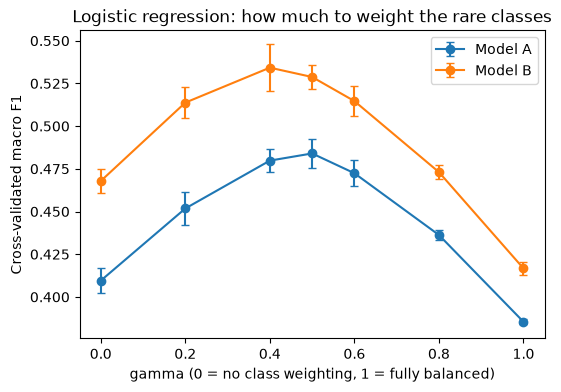

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for name, grid in [("Model A", grid_A), ("Model B", grid_B)]:
    ax.errorbar(GAMMAS, grid.cv_results_["mean_test_score"], yerr=grid.cv_results_["std_test_score"], marker="o", capsize=3, label=name)
ax.set_xlabel("gamma (0 = no class weighting, 1 = fully balanced)")
ax.set_ylabel("Cross-validated macro F1")
ax.set_title("Logistic regression: how much to weight the rare classes")
ax.legend()
fig.savefig("../plots/lr_gamma_curve.png", dpi=200, bbox_inches="tight")

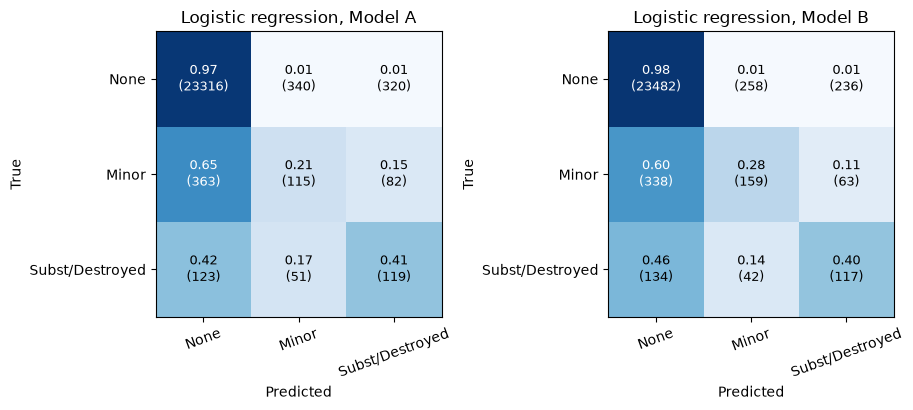

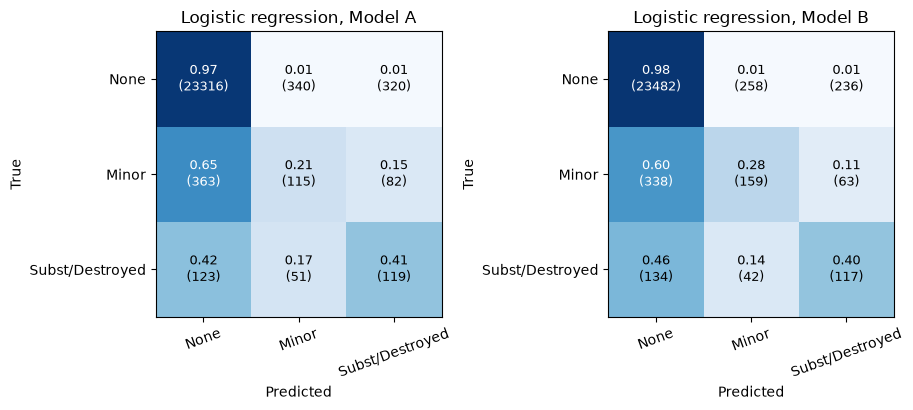

In [17]:
plot_confusion_matrices({"Logistic regression, Model A": regression_model_weighted_A, "Logistic regression, Model B": regression_model_weighted_B}, Xtest, ytest, "../plots/cm_logistic_regression.png")